# Logistic Regression Baseline for UFC Winner Prediction

This notebook builds a baseline logistic regression model using the processed fight datasets.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`Pipeline`, `StandardScaler`, `LogisticRegression`).
4. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, and classification report).
5. Saving trained models (`joblib`).

In [25]:
# Imports
from pathlib import Path

import numpy as np

import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths and reads train, validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 processed CSV files.

In [26]:
# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = DATA_DIR / "Logistic_Regression_Outputs"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "fights_training.csv"
val_path = DATA_DIR / "fights_validation.csv"
val_exp1_path = DATA_DIR / "fights_validation_exp1.csv"
val_exp2_path = DATA_DIR / "fights_validation_exp2.csv"
test_path = DATA_DIR / "fights_testing.csv"
test_exp1_path = DATA_DIR / "fights_testing_exp1.csv"
test_exp2_path = DATA_DIR / "fights_testing_exp2.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
val_exp1_df = pd.read_csv(val_exp1_path)
val_exp2_df = pd.read_csv(val_exp2_path)
test_df = pd.read_csv(test_path)
test_exp1_df = pd.read_csv(test_exp1_path)
test_exp2_df = pd.read_csv(test_exp2_path)


## Define Target Column and the Feature Columns and Split Each Data Frame to X and Y


In [ ]:
TARGET = "winner"
# Exclude metadata columns from features used by the model
exclude_from_features = {TARGET, 'fight_id', 'is_mirror'}
features = [col for col in train_df.columns if col not in exclude_from_features]
print(f"Features ({len(features)}): {features}")

x_train = train_df[features]
y_train = train_df[TARGET]

x_val = val_df.reindex(columns=features, fill_value=0)
y_val = val_df[TARGET]

x_val_exp1 = val_exp1_df.reindex(columns=features, fill_value=0)
y_val_exp1 = val_exp1_df[TARGET]

x_val_exp2 = val_exp2_df.reindex(columns=features, fill_value=0)
y_val_exp2 = val_exp2_df[TARGET]

x_test = test_df.reindex(columns=features, fill_value=0)
y_test = test_df[TARGET]

x_test_exp1 = test_exp1_df.reindex(columns=features, fill_value=0)
y_test_exp1 = test_exp1_df[TARGET]

x_test_exp2 = test_exp2_df.reindex(columns=features, fill_value=0)
y_test_exp2 = test_exp2_df[TARGET]


Features (64): ['f1_age_during', 'f2_age_during', 'mens_class_encoded', 'womens_class_encoded', 'f1_orthodox', 'f1_southpaw', 'f1_switch', 'f2_orthodox', 'f2_southpaw', 'f2_switch', 'diff_fighter_dob', 'diff_height_cm', 'diff_knockdowns', 'diff_sig_strike_atts', 'diff_sig_strikes', 'diff_tot_strike_atts', 'diff_tot_strikes', 'diff_takedown_atts', 'diff_takedowns', 'diff_submissions', 'diff_reversals', 'diff_ctrl_time', 'diff_head_strike_atts', 'diff_head_strikes', 'diff_body_strike_atts', 'diff_body_strikes', 'diff_leg_strike_atts', 'diff_leg_strikes', 'diff_dist_strike_atts', 'diff_dist_strikes', 'diff_clinch_atts', 'diff_clinchs', 'diff_ground_atts', 'diff_grounds', 'diff_total_fight_time', 'diff_experience', 'diff_wins', 'diff_losses', 'diff_fighter_weight_lbs', 'diff_fighter_reach_cm', 'diff_knockdowns_last4', 'diff_sig_strike_atts_last4', 'diff_sig_strikes_last4', 'diff_tot_strike_atts_last4', 'diff_tot_strikes_last4', 'diff_takedown_atts_last4', 'diff_takedowns_last4', 'diff_subm

## Build Scikit-Learn Pipline
1. Standarize data to ensure each feature has a mean of zero and a standard deviation of 1 (Standard Scalar)
2. Perform Logistic Regression

In [38]:
pipeline = Pipeline(steps=[("scaler", StandardScaler()),
    ("log_reg", LogisticRegression(random_state=42, max_iter=2000, C=0.10))])
pipeline.fit(x_train, y_train)
val_pred = pipeline.predict(x_val)
val_prob = pipeline.predict_proba(x_val)[:, 1]
val_exp1_pred = pipeline.predict(x_val_exp1)
val_exp1_prob = pipeline.predict_proba(x_val_exp1)[:, 1]
val_exp2_pred = pipeline.predict(x_val_exp2)
val_exp2_prob = pipeline.predict_proba(x_val_exp2)[:, 1]

# Test predictions
test_pred = pipeline.predict(x_test)
test_prob = pipeline.predict_proba(x_test)[:, 1]
test_exp1_pred = pipeline.predict(x_test_exp1)
test_exp1_prob = pipeline.predict_proba(x_test_exp1)[:, 1]
test_exp2_pred = pipeline.predict(x_test_exp2)
test_exp2_prob = pipeline.predict_proba(x_test_exp2)[:, 1]


In [39]:
# Save split-level predictions and probabilities to CSV
validation_output_path = OUTPUT_DIR / "logistic_regression_validation_predictions.csv"
validation_exp1_output_path = OUTPUT_DIR / "logistic_regression_validation_exp1_predictions.csv"
validation_exp2_output_path = OUTPUT_DIR / "logistic_regression_validation_exp2_predictions.csv"
test_output_path = OUTPUT_DIR / "logistic_regression_test_predictions.csv"
test_exp1_output_path = OUTPUT_DIR / "logistic_regression_test_exp1_predictions.csv"
test_exp2_output_path = OUTPUT_DIR / "logistic_regression_test_exp2_predictions.csv"

validation_results = x_val.reset_index(drop=True).copy()
validation_results["actual_label"] = y_val.reset_index(drop=True)
validation_results["predicted_label"] = val_pred
validation_results["prob_fighter_a_win"] = val_prob
validation_results["prob_fighter_b_win"] = 1 - val_prob
validation_results["correct"] = (validation_results["actual_label"] == validation_results["predicted_label"]).astype(int)

validation_exp1_results = x_val_exp1.reset_index(drop=True).copy()
validation_exp1_results["actual_label"] = y_val_exp1.reset_index(drop=True)
validation_exp1_results["predicted_label"] = val_exp1_pred
validation_exp1_results["prob_fighter_a_win"] = val_exp1_prob
validation_exp1_results["prob_fighter_b_win"] = 1 - val_exp1_prob
validation_exp1_results["correct"] = (validation_exp1_results["actual_label"] == validation_exp1_results["predicted_label"]).astype(int)

validation_exp2_results = x_val_exp2.reset_index(drop=True).copy()
validation_exp2_results["actual_label"] = y_val_exp2.reset_index(drop=True)
validation_exp2_results["predicted_label"] = val_exp2_pred
validation_exp2_results["prob_fighter_a_win"] = val_exp2_prob
validation_exp2_results["prob_fighter_b_win"] = 1 - val_exp2_prob
validation_exp2_results["correct"] = (validation_exp2_results["actual_label"] == validation_exp2_results["predicted_label"]).astype(int)

test_results = x_test.reset_index(drop=True).copy()
test_results["actual_label"] = y_test.reset_index(drop=True)
test_results["predicted_label"] = test_pred
test_results["prob_fighter_a_win"] = test_prob
test_results["prob_fighter_b_win"] = 1 - test_prob
test_results["correct"] = (test_results["actual_label"] == test_results["predicted_label"]).astype(int)

test_exp1_results = x_test_exp1.reset_index(drop=True).copy()
test_exp1_results["actual_label"] = y_test_exp1.reset_index(drop=True)
test_exp1_results["predicted_label"] = test_exp1_pred
test_exp1_results["prob_fighter_a_win"] = test_exp1_prob
test_exp1_results["prob_fighter_b_win"] = 1 - test_exp1_prob
test_exp1_results["correct"] = (test_exp1_results["actual_label"] == test_exp1_results["predicted_label"]).astype(int)

test_exp2_results = x_test_exp2.reset_index(drop=True).copy()
test_exp2_results["actual_label"] = y_test_exp2.reset_index(drop=True)
test_exp2_results["predicted_label"] = test_exp2_pred
test_exp2_results["prob_fighter_a_win"] = test_exp2_prob
test_exp2_results["prob_fighter_b_win"] = 1 - test_exp2_prob
test_exp2_results["correct"] = (test_exp2_results["actual_label"] == test_exp2_results["predicted_label"]).astype(int)

# Attach fight_id from source splits (or synthesize if missing).
def _attach_fight_id(results_df, src_df, split_name):
    if 'fight_id' in src_df.columns:
        results_df['fight_id'] = src_df['fight_id'].reset_index(drop=True)
    else:
        results_df['fight_id'] = [f'{split_name}_' + str(i+1) for i in range(len(results_df))]
    return results_df

validation_results = _attach_fight_id(validation_results, val_df, 'validation')
validation_exp1_results = _attach_fight_id(validation_exp1_results, val_exp1_df, 'validation_exp1')
validation_exp2_results = _attach_fight_id(validation_exp2_results, val_exp2_df, 'validation_exp2')
test_results = _attach_fight_id(test_results, test_df, 'test')
test_exp1_results = _attach_fight_id(test_exp1_results, test_exp1_df, 'test_exp1')
test_exp2_results = _attach_fight_id(test_exp2_results, test_exp2_df, 'test_exp2')

validation_results.to_csv(validation_output_path, index=False)
validation_exp1_results.to_csv(validation_exp1_output_path, index=False)
validation_exp2_results.to_csv(validation_exp2_output_path, index=False)
test_results.to_csv(test_output_path, index=False)
test_exp1_results.to_csv(test_exp1_output_path, index=False)
test_exp2_results.to_csv(test_exp2_output_path, index=False)

print(f"Saved validation predictions to: {validation_output_path}")
print(f"Saved validation exp1 predictions to: {validation_exp1_output_path}")
print(f"Saved validation exp2 predictions to: {validation_exp2_output_path}")
print(f"Saved test predictions to: {test_output_path}")
print(f"Saved test exp1 predictions to: {test_exp1_output_path}")
print(f"Saved test exp2 predictions to: {test_exp2_output_path}")

Saved validation predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_predictions.csv
Saved validation exp1 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_exp1_predictions.csv
Saved validation exp2 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_exp2_predictions.csv
Saved test predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_predictions.csv
Saved test exp1 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_exp1_predictions.csv
Saved test exp2 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_exp2_pred

## Metrics and Classification Reports

This code block computes metrics (accuracy, precision, recall, F1, log loss, and ROC-AUC) for validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 splits, then prints class-by-class reports.

Log-Loss Comparison and Betting Simulation

In [40]:
from pathlib import Path

import numpy as np
import pandas as pd

# Define project paths and load files
project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
data_dir = globals().get("DATA_DIR", project_root / "data" / "processed")
output_dir = globals().get("OUTPUT_DIR", data_dir / "Logistic_Regression_Outputs")

odds = pd.read_csv(data_dir / "odds_cleaned.csv")
odds["fight_id_int"] = pd.to_numeric(odds["fight_id"], errors="coerce")

prediction_candidates = [
    ("standard", output_dir / "logistic_regression_test_predictions.csv"),
    ("exp1", output_dir / "logistic_regression_test_exp1_predictions.csv"),
    ("exp2", output_dir / "logistic_regression_test_exp2_predictions.csv"),
]


def load_prediction_frame(prediction_path):
    frame = pd.read_csv(prediction_path).copy()
    frame["fight_id_int"] = pd.to_numeric(frame["fight_id"], errors="coerce")
    frame = frame.dropna(subset=["fight_id_int"]).copy()
    frame["fight_id_int"] = frame["fight_id_int"].astype(int)
    frame = frame.drop_duplicates(subset=["fight_id_int"]).copy()
    return frame


candidates = []
for split_name, prediction_path in prediction_candidates:
    preds = load_prediction_frame(prediction_path)
    matched = preds.merge(odds, on="fight_id_int", how="inner", suffixes=("", "_odds"))
    unique_match_count = matched["fight_id_int"].nunique()
    candidates.append((unique_match_count, split_name, preds, matched))

best_match_count, best_split_name, preds, matched = max(candidates, key=lambda item: item[0])

if best_match_count == 0:
    raise ValueError("No prediction file matched odds_cleaned on fight_id; cannot run betting simulation safely.")

print(f"Using {best_split_name} predictions for betting simulation ({best_match_count} matched fights).")

# Align market probabilities and odds to Fighter A / Fighter B
matched["market_prob_a"] = np.where(matched["r_is_f1"] == 1, matched["r_prob"], matched["b_prob"])
matched["market_prob_b"] = np.where(matched["r_is_f1"] == 1, matched["b_prob"], matched["r_prob"])
matched["odds_a"] = np.where(matched["r_is_f1"] == 1, matched["R_odds"], matched["B_odds"])
matched["odds_b"] = np.where(matched["r_is_f1"] == 1, matched["B_odds"], matched["R_odds"])

# LOG-LOSS COMPARISON
eps = 1e-15


def per_logloss(y, p):
    p = float(np.clip(p, eps, 1 - eps))
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

matched["ll_model"] = matched.apply(lambda r: per_logloss(r["actual_label"], r["prob_fighter_a_win"]), axis=1)
matched["ll_market"] = matched.apply(lambda r: per_logloss(r["actual_label"], r["market_prob_a"]), axis=1)

print("--- Log-Loss Comparison ---")
print(f"Average log-loss — Model:  {matched['ll_model'].mean():.5f}")
print(f"Average log-loss — Market: {matched['ll_market'].mean():.5f}")
print("---------------------------\n")


# BETTING SIMULATION (Value Betting)
WAGER = 10.0
EDGE_THRESHOLD = 0.05  # Only bet if the edge is > 5%

# Calculate Model Edge
matched["edge_a"] = matched["prob_fighter_a_win"] - matched["market_prob_a"]
matched["edge_b"] = matched["prob_fighter_b_win"] - matched["market_prob_b"]

def get_payout(odds, win, wager):
    if not win:
        return -wager
    if odds > 0:
        return wager * (odds / 100.0)
    elif odds < 0:
        return wager * (100.0 / abs(odds))
    return 0

profits = []
bets_placed = []

for _, row in matched.iterrows():
    if row["edge_a"] > EDGE_THRESHOLD and row["edge_a"] > row["edge_b"]:
        bets_placed.append("A")
        win = row["actual_label"] == 1
        profits.append(get_payout(row["odds_a"], win, WAGER))

    elif row["edge_b"] > EDGE_THRESHOLD and row["edge_b"] > row["edge_a"]:
        bets_placed.append("B")
        win = row["actual_label"] == 0
        profits.append(get_payout(row["odds_b"], win, WAGER))

    else:
        # No bet placed
        bets_placed.append(None)
        profits.append(0)

matched["bet_placed"] = bets_placed
matched["profit"] = profits

# Filter to only the matches where we placed a wager
placed_bets = matched.dropna(subset=["bet_placed"]).copy()

# Summary
total_wagered = len(placed_bets) * WAGER
total_profit = placed_bets["profit"].sum()

after_wager = total_profit / total_wagered * 100 if total_wagered else 0.0

print("--- Betting Simulation ---")
print(f"Total Matches Analyzed: {len(matched)}")
print(f"Total Bets Placed: {len(placed_bets)}")
print(f"Total Wagered: ${total_wagered:.2f}")
print(f"Total Profit/Loss: ${total_profit:.2f}")
print(f"ROI: {after_wager:.2f}%")

Using standard predictions for betting simulation (646 matched fights).
--- Log-Loss Comparison ---
Average log-loss — Model:  0.66936
Average log-loss — Market: 0.62158
---------------------------

--- Betting Simulation ---
Total Matches Analyzed: 646
Total Bets Placed: 442
Total Wagered: $4420.00
Total Profit/Loss: $135.18
ROI: 3.06%


In [41]:
val_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall": recall_score(y_val, val_pred, zero_division=0),
    "f1": f1_score(y_val, val_pred, zero_division=0),
    "log_loss": log_loss(y_val, val_prob),
    "roc_auc": roc_auc_score(y_val, val_prob),
}

val_exp1_metrics = {
    "accuracy": accuracy_score(y_val_exp1, val_exp1_pred),
    "precision": precision_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "recall": recall_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "f1": f1_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "log_loss": log_loss(y_val_exp1, val_exp1_prob),
    "roc_auc": roc_auc_score(y_val_exp1, val_exp1_prob),
}

val_exp2_metrics = {
    "accuracy": accuracy_score(y_val_exp2, val_exp2_pred),
    "precision": precision_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "recall": recall_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "f1": f1_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "log_loss": log_loss(y_val_exp2, val_exp2_prob),
    "roc_auc": roc_auc_score(y_val_exp2, val_exp2_prob),
}

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "log_loss": log_loss(y_test, test_prob),
    "roc_auc": roc_auc_score(y_test, test_prob),
}

test_exp1_metrics = {
    "accuracy": accuracy_score(y_test_exp1, test_exp1_pred),
    "precision": precision_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "recall": recall_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "f1": f1_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "log_loss": log_loss(y_test_exp1, test_exp1_prob),
    "roc_auc": roc_auc_score(y_test_exp1, test_exp1_prob),
}

test_exp2_metrics = {
    "accuracy": accuracy_score(y_test_exp2, test_exp2_pred),
    "precision": precision_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "recall": recall_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "f1": f1_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "log_loss": log_loss(y_test_exp2, test_exp2_prob),
    "roc_auc": roc_auc_score(y_test_exp2, test_exp2_prob),
}

metrics_df = pd.DataFrame(
    [
        val_metrics,
        val_exp1_metrics,
        val_exp2_metrics,
        test_metrics,
        test_exp1_metrics,
        test_exp2_metrics,
    ],
    index=[
        "validation",
        "validation_exp1",
        "validation_exp2",
        "test",
        "test_exp1",
        "test_exp2",
    ],
)
display(metrics_df)

print("\nValidation classification report:")
print(classification_report(y_val, val_pred, digits=4))

print("\nValidation exp1 classification report:")
print(classification_report(y_val_exp1, val_exp1_pred, digits=4))

print("\nValidation exp2 classification report:")
print(classification_report(y_val_exp2, val_exp2_pred, digits=4))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, digits=4))

print("\nTest exp1 classification report:")
print(classification_report(y_test_exp1, test_exp1_pred, digits=4))

print("\nTest exp2 classification report:")
print(classification_report(y_test_exp2, test_exp2_pred, digits=4))

,accuracy,precision,recall,f1,log_loss,roc_auc
validation,0.609060,0.609060,0.609060,0.609060,0.652983,0.653436
validation_exp1,0.621053,0.621053,0.621053,0.621053,0.634885,0.684441
validation_exp2,0.680108,0.680108,0.680108,0.680108,0.610280,0.728343
test,0.634228,0.634228,0.634228,0.634228,0.630031,0.695936
test_exp1,0.662105,0.662105,0.662105,0.662105,0.618003,0.714153
test_exp2,0.626005,0.626005,0.626005,0.626005,0.631035,0.697182



Validation classification report:
              precision    recall  f1-score   support

           0     0.6091    0.6091    0.6091       596
           1     0.6091    0.6091    0.6091       596

    accuracy                         0.6091      1192
   macro avg     0.6091    0.6091    0.6091      1192
weighted avg     0.6091    0.6091    0.6091      1192


Validation exp1 classification report:
              precision    recall  f1-score   support

           0     0.6211    0.6211    0.6211       475
           1     0.6211    0.6211    0.6211       475

    accuracy                         0.6211       950
   macro avg     0.6211    0.6211    0.6211       950
weighted avg     0.6211    0.6211    0.6211       950


Validation exp2 classification report:
              precision    recall  f1-score   support

           0     0.6801    0.6801    0.6801       372
           1     0.6801    0.6801    0.6801       372

    accuracy                         0.6801       744
   macro avg 

## Cross-Entropy Evaluation and Visualization

This section computes per-fight cross entropy from the predicted probabilities and compares distributions in two separate groups:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Lower values indicate better calibrated predictions.

,split,mean,median,std
0,test,0.630031,0.551326,0.351947
1,test_exp1,0.618003,0.541477,0.341508
2,test_exp2,0.631035,0.554828,0.375523
3,validation,0.652983,0.600885,0.349929
4,validation_exp1,0.634885,0.559752,0.349396
5,validation_exp2,0.610280,0.533444,0.335987


/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_25523/2385771214.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


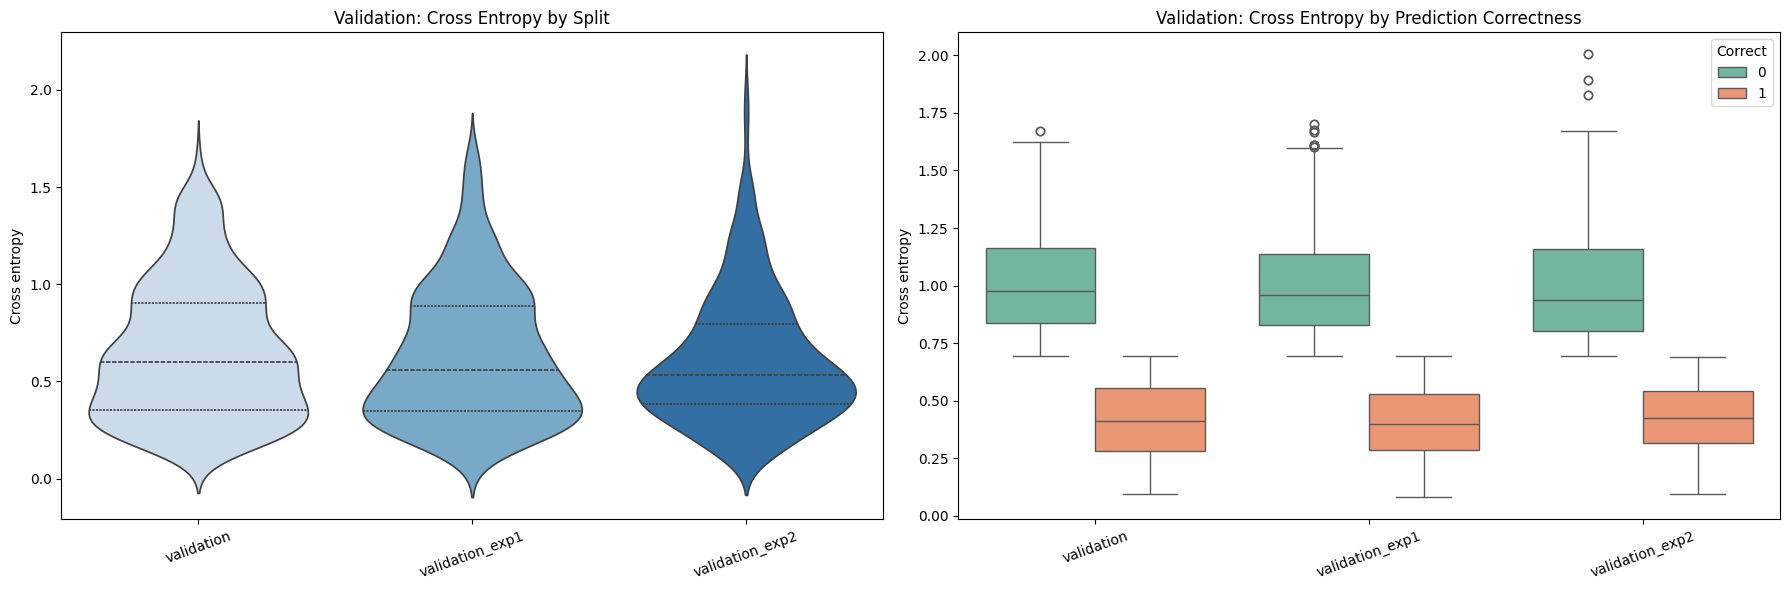

/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_25523/2385771214.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


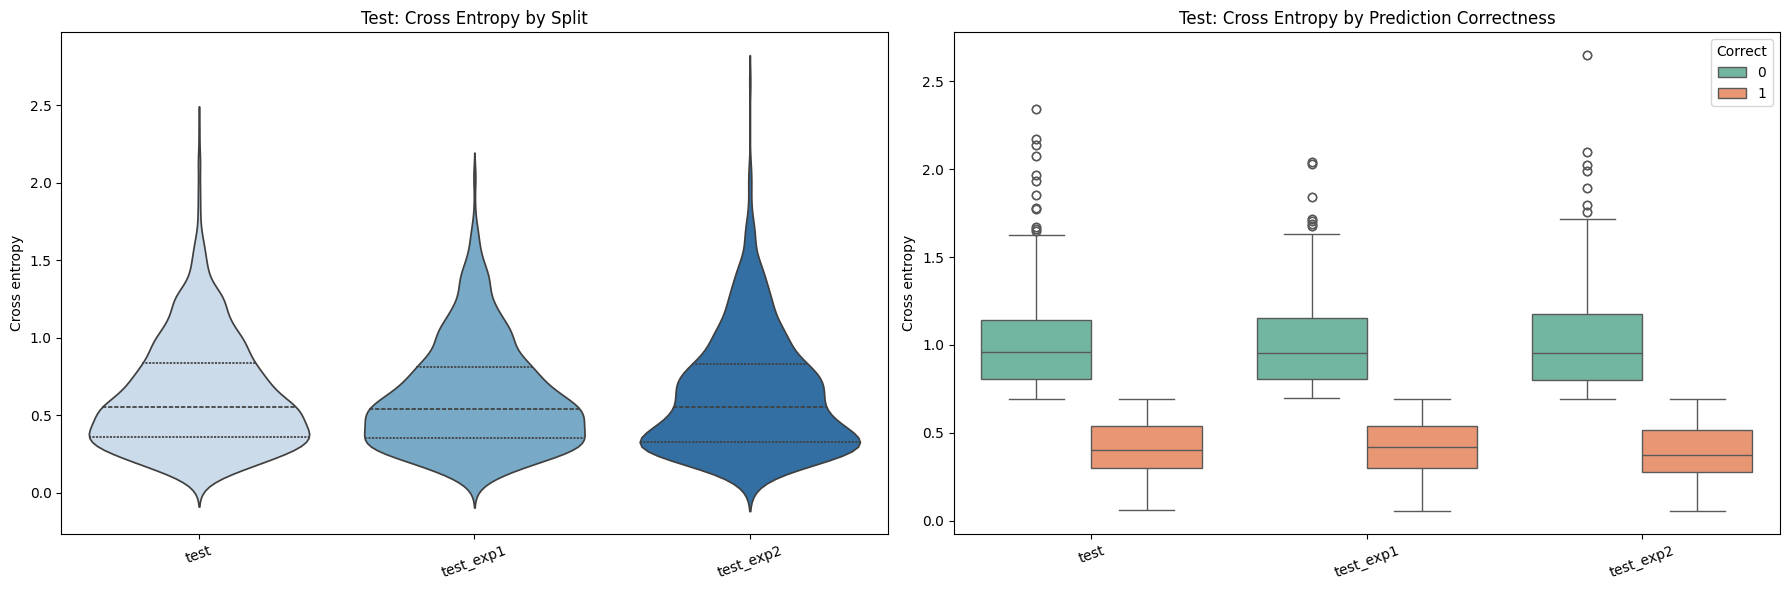

In [42]:
def binary_cross_entropy(y_true, y_prob):
    y_true_arr = np.asarray(y_true, dtype=float)
    y_prob_arr = np.clip(np.asarray(y_prob, dtype=float), 1e-15, 1 - 1e-15)
    return -(y_true_arr * np.log(y_prob_arr) + (1 - y_true_arr) * np.log(1 - y_prob_arr))


def build_ce_frame(split_name, y_true, y_pred, y_prob):
    frame = pd.DataFrame({
        "split": split_name,
        "actual_label": y_true.reset_index(drop=True),
        "predicted_label": y_pred,
        "prob_fighter_a_win": y_prob,
    })
    frame["cross_entropy"] = binary_cross_entropy(frame["actual_label"], frame["prob_fighter_a_win"])
    frame["correct"] = (frame["actual_label"] == frame["predicted_label"]).astype(int)
    return frame


validation_ce = build_ce_frame("validation", y_val, val_pred, val_prob)
validation_exp1_ce = build_ce_frame("validation_exp1", y_val_exp1, val_exp1_pred, val_exp1_prob)
validation_exp2_ce = build_ce_frame("validation_exp2", y_val_exp2, val_exp2_pred, val_exp2_prob)
test_ce = build_ce_frame("test", y_test, test_pred, test_prob)
test_exp1_ce = build_ce_frame("test_exp1", y_test_exp1, test_exp1_pred, test_exp1_prob)
test_exp2_ce = build_ce_frame("test_exp2", y_test_exp2, test_exp2_pred, test_exp2_prob)

ce_df = pd.concat(
    [validation_ce, validation_exp1_ce, validation_exp2_ce, test_ce, test_exp1_ce, test_exp2_ce],
    ignore_index=True,
)
summary_df = ce_df.groupby("split")["cross_entropy"].agg(["mean", "median", "std"]).reset_index()
display(summary_df)


def plot_cross_entropy_by_group(dataframe, split_order, group_title):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    sns.violinplot(
        data=dataframe,
        x="split",
        y="cross_entropy",
        order=split_order,
        inner="quartile",
        palette="Blues",
        ax=axes[0],
    )
    axes[0].set_title(f"{group_title}: Cross Entropy by Split")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Cross entropy")
    axes[0].tick_params(axis="x", rotation=20)

    sns.boxplot(
        data=dataframe,
        x="split",
        y="cross_entropy",
        hue="correct",
        order=split_order,
        palette="Set2",
        ax=axes[1],
    )
    axes[1].set_title(f"{group_title}: Cross Entropy by Prediction Correctness")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Cross entropy")
    axes[1].tick_params(axis="x", rotation=20)
    axes[1].legend(title="Correct", loc="upper right")

    plt.tight_layout()
    plt.show()


validation_splits = ["validation", "validation_exp1", "validation_exp2"]
test_splits = ["test", "test_exp1", "test_exp2"]

plot_cross_entropy_by_group(
    ce_df[ce_df["split"].isin(validation_splits)],
    validation_splits,
    "Validation",
)
plot_cross_entropy_by_group(
    ce_df[ce_df["split"].isin(test_splits)],
    test_splits,
    "Test",
)

## ROC-AUC Evaluation and ROC Curves

This section reports ROC-AUC for all splits and plots ROC curves in two separate figures:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Curves closer to the top-left corner indicate stronger class separation.

Validation ROC-AUC: 0.6534
Validation exp1 ROC-AUC: 0.6844
Validation exp2 ROC-AUC: 0.7283
Test ROC-AUC: 0.6959
Test exp1 ROC-AUC: 0.7142
Test exp2 ROC-AUC: 0.6972


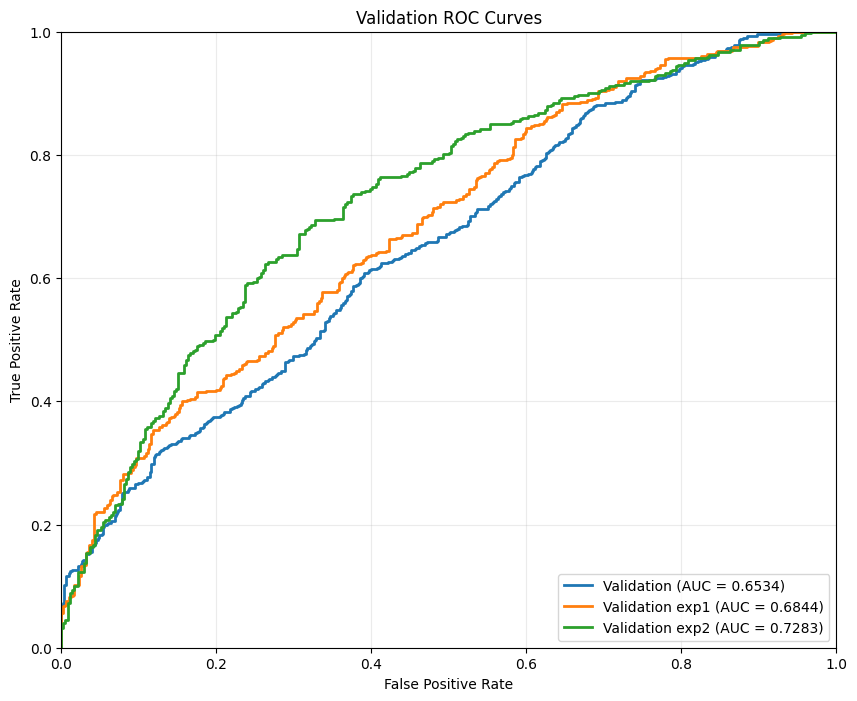

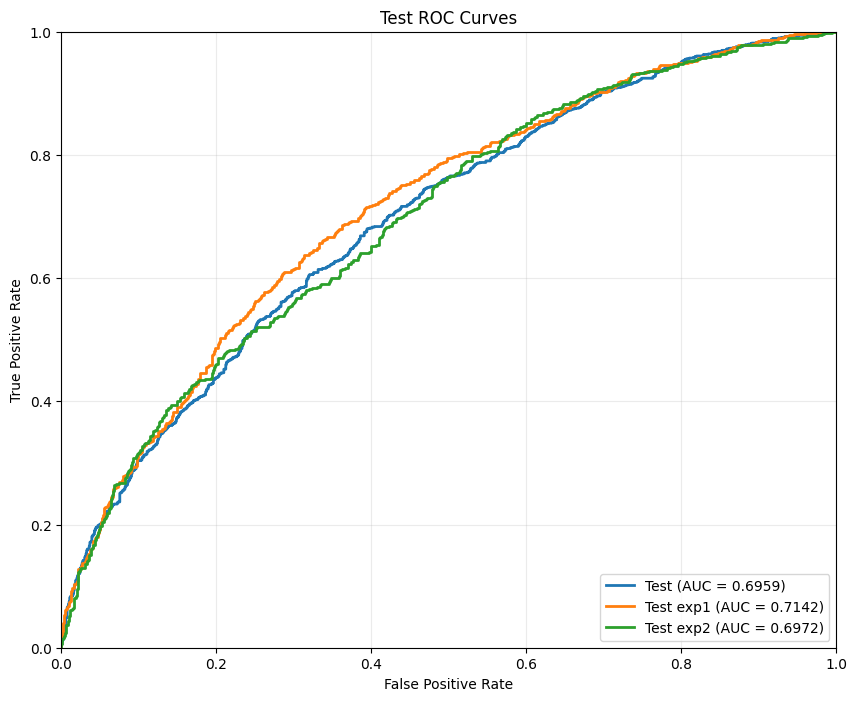

In [43]:
val_auc = roc_auc_score(y_val, val_prob)
val_exp1_auc = roc_auc_score(y_val_exp1, val_exp1_prob)
val_exp2_auc = roc_auc_score(y_val_exp2, val_exp2_prob)
test_auc = roc_auc_score(y_test, test_prob)
test_exp1_auc = roc_auc_score(y_test_exp1, test_exp1_prob)
test_exp2_auc = roc_auc_score(y_test_exp2, test_exp2_prob)

print(f"Validation ROC-AUC: {val_auc:.4f}")
print(f"Validation exp1 ROC-AUC: {val_exp1_auc:.4f}")
print(f"Validation exp2 ROC-AUC: {val_exp2_auc:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Test exp1 ROC-AUC: {test_exp1_auc:.4f}")
print(f"Test exp2 ROC-AUC: {test_exp2_auc:.4f}")

val_fpr, val_tpr, _ = roc_curve(y_val, val_prob)
val_exp1_fpr, val_exp1_tpr, _ = roc_curve(y_val_exp1, val_exp1_prob)
val_exp2_fpr, val_exp2_tpr, _ = roc_curve(y_val_exp2, val_exp2_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)
test_exp1_fpr, test_exp1_tpr, _ = roc_curve(y_test_exp1, test_exp1_prob)
test_exp2_fpr, test_exp2_tpr, _ = roc_curve(y_test_exp2, test_exp2_prob)

plt.figure(figsize=(10, 8))
plt.plot(val_fpr, val_tpr, linewidth=2, label=f"Validation (AUC = {val_auc:.4f})")
plt.plot(val_exp1_fpr, val_exp1_tpr, linewidth=2, label=f"Validation exp1 (AUC = {val_exp1_auc:.4f})")
plt.plot(val_exp2_fpr, val_exp2_tpr, linewidth=2, label=f"Validation exp2 (AUC = {val_exp2_auc:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 8))
plt.plot(test_fpr, test_tpr, linewidth=2, label=f"Test (AUC = {test_auc:.4f})")
plt.plot(test_exp1_fpr, test_exp1_tpr, linewidth=2, label=f"Test exp1 (AUC = {test_exp1_auc:.4f})")
plt.plot(test_exp2_fpr, test_exp2_tpr, linewidth=2, label=f"Test exp2 (AUC = {test_exp2_auc:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

## Evaluation and Coefficient Interpretation

The next code block does two things:
1. Plots confusion matrices for validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 so you can compare true/false predictions by class across splits.
2. Extracts logistic regression coefficients and displays the top features by absolute magnitude to highlight the strongest model signals.

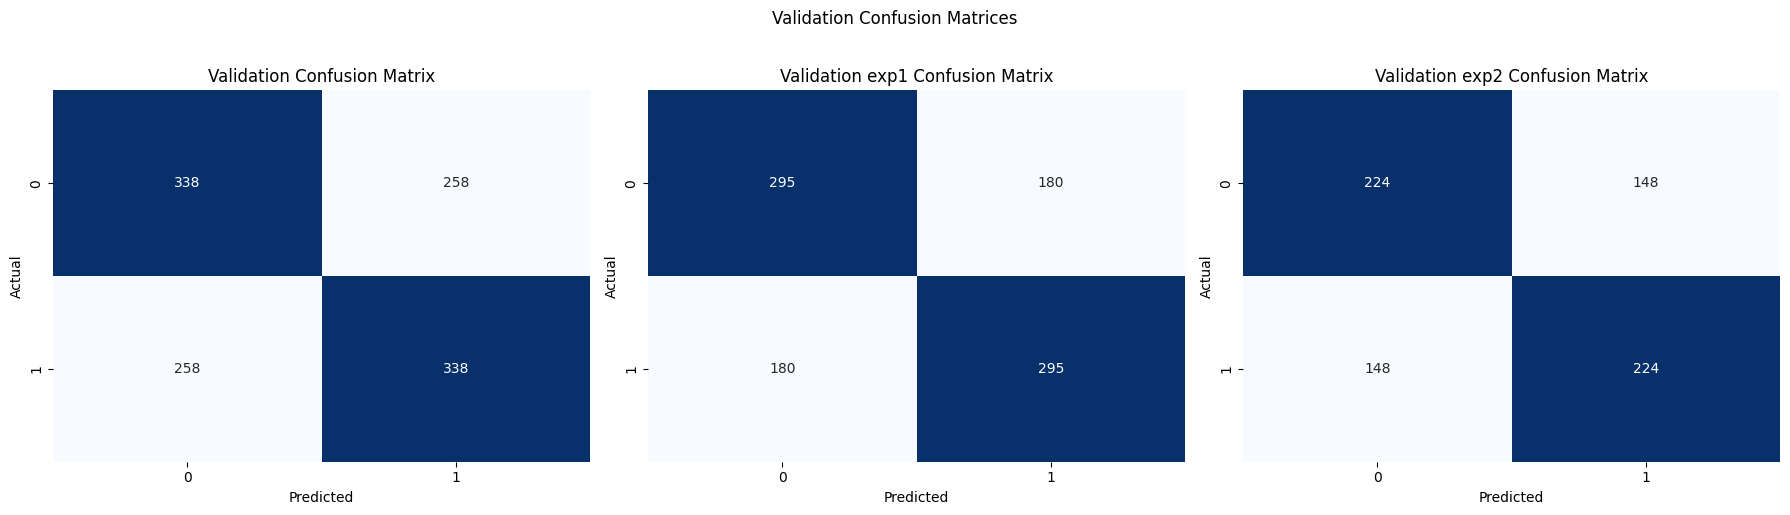

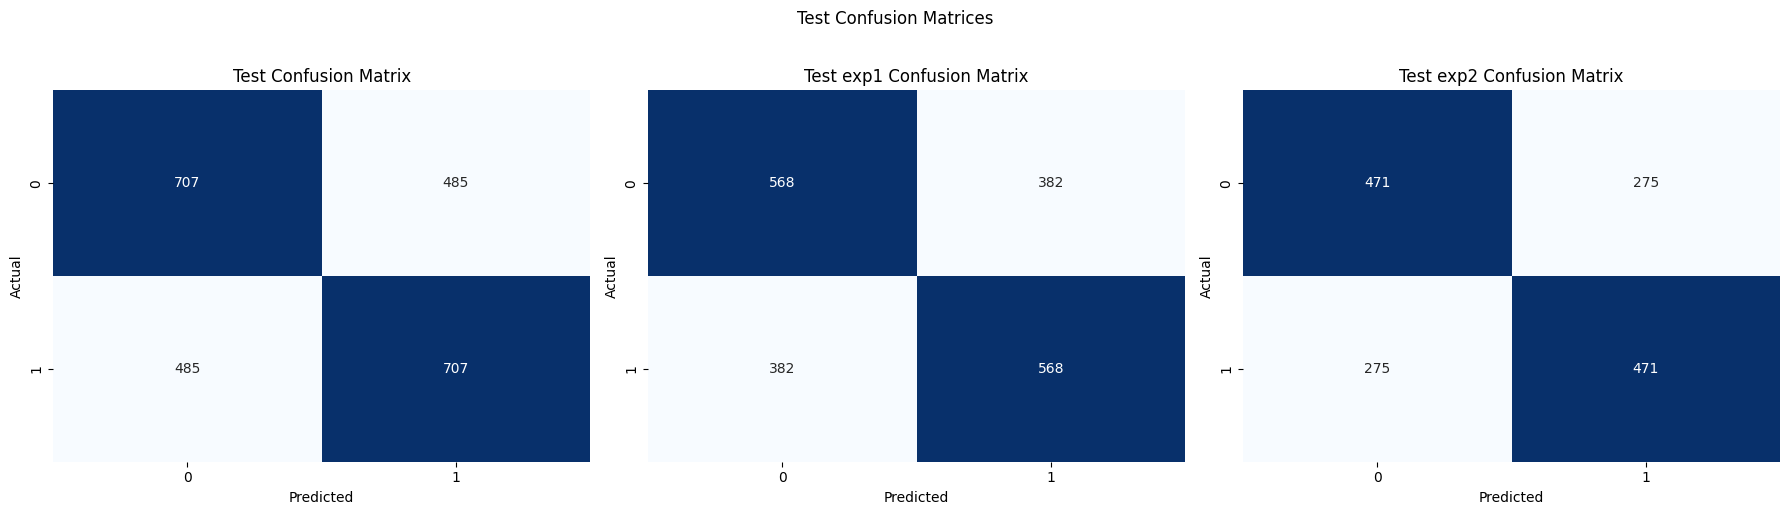

/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_25523/2720333816.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=positive_coefs, x="coefficient", y="feature", palette="Greens_r", ax=axes[0])
/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_25523/2720333816.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=negative_coefs, x="coefficient", y="feature", palette="Reds_r", ax=axes[1])


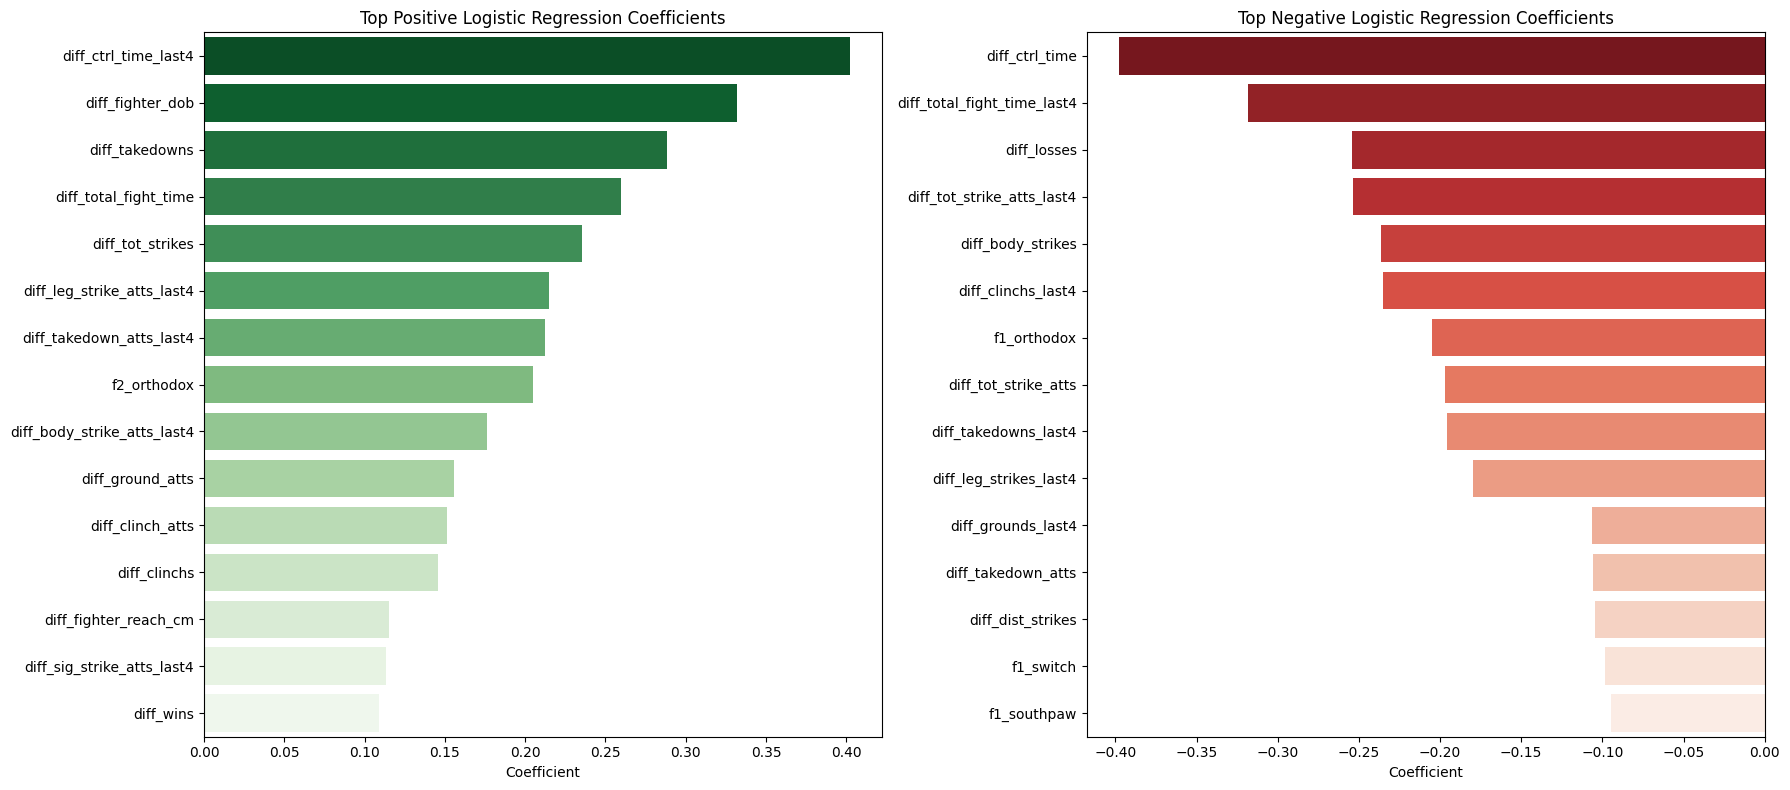

Top 15 features by absolute coefficient:


,feature,coefficient,abs_coef
49,diff_ctrl_time_last4,0.402148,0.402148
21,diff_ctrl_time,-0.397760,0.397760
10,diff_fighter_dob,0.332053,0.332053
62,diff_total_fight_time_last4,-0.318270,0.318270
18,diff_takedowns,0.288096,0.288096
34,diff_total_fight_time,0.259921,0.259921
37,diff_losses,-0.254057,0.254057
43,diff_tot_strike_atts_last4,-0.253295,0.253295
25,diff_body_strikes,-0.236591,0.236591
16,diff_tot_strikes,0.235366,0.235366


In [34]:
validation_confusion_inputs = [
    ("Validation", y_val, val_pred),
    ("Validation exp1", y_val_exp1, val_exp1_pred),
    ("Validation exp2", y_val_exp2, val_exp2_pred),
]

test_confusion_inputs = [
    ("Test", y_test, test_pred),
    ("Test exp1", y_test_exp1, test_exp1_pred),
    ("Test exp2", y_test_exp2, test_exp2_pred),
]


def plot_confusion_group(confusion_inputs, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (split_name, y_true, y_pred) in zip(axes.flatten(), confusion_inputs):
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{split_name} Confusion Matrix")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    fig.suptitle(f"{title_prefix} Confusion Matrices", y=1.02)
    plt.tight_layout()
    plt.show()


plot_confusion_group(validation_confusion_inputs, "Validation")
plot_confusion_group(test_confusion_inputs, "Test")

coef = pipeline.named_steps["log_reg"].coef_[0]
coef_df = pd.DataFrame({"feature": features, "coefficient": coef})
coef_df["abs_coef"] = coef_df["coefficient"].abs()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

positive_coefs = coef_df.sort_values("coefficient", ascending=False).head(15)
negative_coefs = coef_df.sort_values("coefficient", ascending=True).head(15)

sns.barplot(data=positive_coefs, x="coefficient", y="feature", palette="Greens_r", ax=axes[0])
axes[0].set_title("Top Positive Logistic Regression Coefficients")
axes[0].set_xlabel("Coefficient")
axes[0].set_ylabel("")

sns.barplot(data=negative_coefs, x="coefficient", y="feature", palette="Reds_r", ax=axes[1])
axes[1].set_title("Top Negative Logistic Regression Coefficients")
axes[1].set_xlabel("Coefficient")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print("Top 15 features by absolute coefficient:")
display(coef_df.sort_values("abs_coef", ascending=False).head(15))

## Feature-Focused Accuracy Plots

This code block builds feature-level diagnostics from top coefficients by plotting accuracy across value bins for top features in two separate groups:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Bins are ranges of data values grouped together to calculate model accuracy for samples in each group.

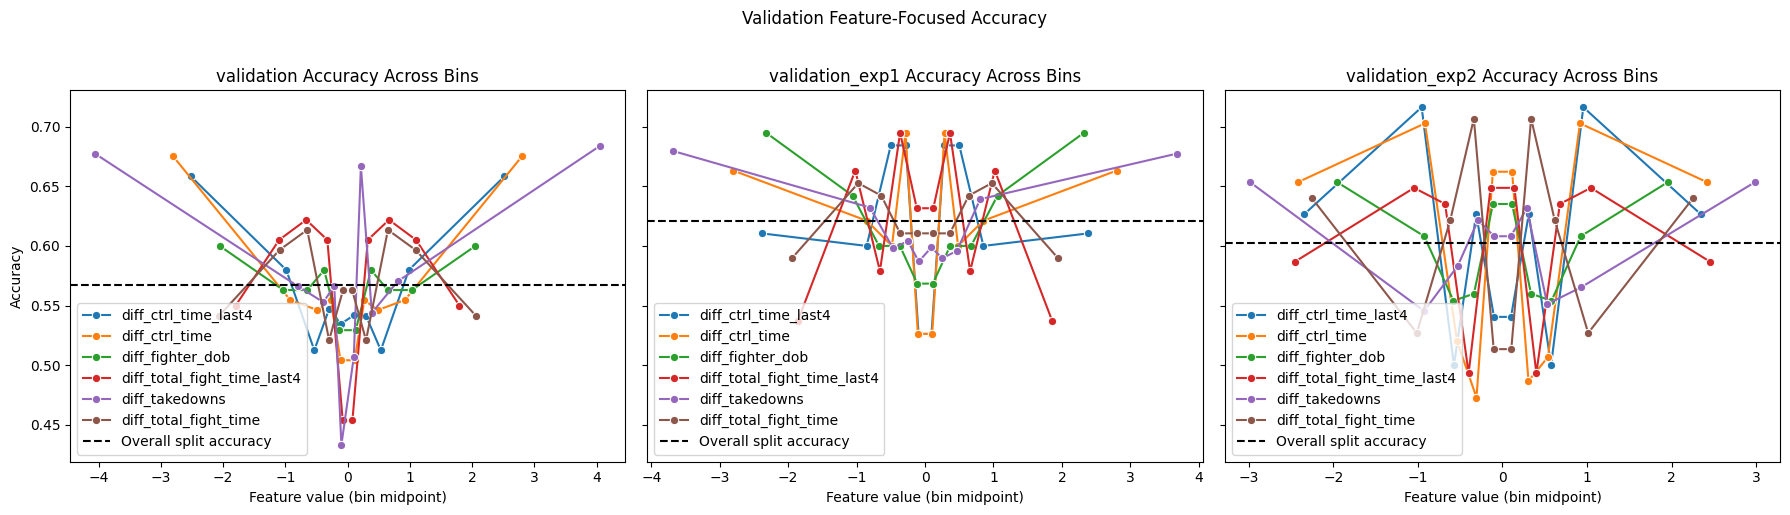

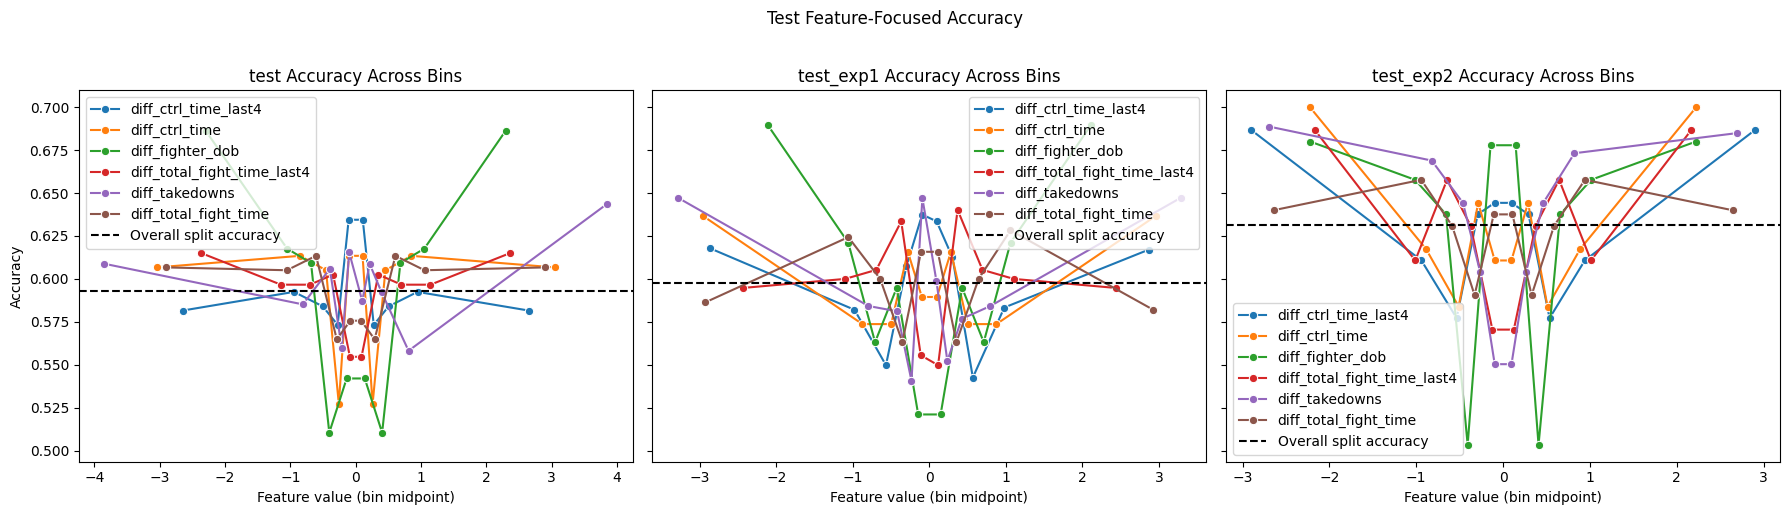

In [35]:
# Top n features for focused accuracy plots
top_n = 6
top_features = coef_df.sort_values("abs_coef", ascending=False).head(top_n)["feature"].tolist()

split_feature_inputs = {
    "validation": (x_val, y_val, val_pred),
    "validation_exp1": (x_val_exp1, y_val_exp1, val_exp1_pred),
    "validation_exp2": (x_val_exp2, y_val_exp2, val_exp2_pred),
    "test": (x_test, y_test, test_pred),
    "test_exp1": (x_test_exp1, y_test_exp1, test_exp1_pred),
    "test_exp2": (x_test_exp2, y_test_exp2, test_exp2_pred),
}

binned_rows = []
overall_acc_by_split = {}

for split_name, (x_split, y_split, pred_split) in split_feature_inputs.items():
    split_plot_df = x_split[top_features].copy()
    split_plot_df["correct"] = (pred_split == y_split.to_numpy()).astype(int)
    overall_acc_by_split[split_name] = accuracy_score(y_split, pred_split)

    for feature in top_features:
        try:
            bins = pd.qcut(split_plot_df[feature], q=10, duplicates="drop")
        except ValueError:
            continue

        feature_bins = pd.DataFrame({"bin": bins, "correct": split_plot_df["correct"]})
        summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
        summary["feature"] = feature
        summary["split"] = split_name
        summary["bin_mid"] = summary["bin"].apply(lambda interval: interval.mid)
        binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    def plot_feature_accuracy_group(split_order, title_prefix):
        fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
        for ax, split_name in zip(axes.flatten(), split_order):
            split_data = binned_accuracy[binned_accuracy["split"] == split_name]
            if split_data.empty:
                ax.set_title(f"{split_name} (no plottable bins)")
                ax.axis("off")
                continue

            sns.lineplot(
                data=split_data,
                x="bin_mid",
                y="accuracy",
                hue="feature",
                marker="o",
                ax=ax,
            )
            ax.axhline(
                overall_acc_by_split[split_name],
                color="black",
                linestyle="--",
                linewidth=1.5,
                label="Overall split accuracy",
            )
            ax.set_title(f"{split_name} Accuracy Across Bins")
            ax.set_xlabel("Feature value (bin midpoint)")
            ax.set_ylabel("Accuracy")
            ax.legend(loc="best")

        fig.suptitle(f"{title_prefix} Feature-Focused Accuracy", y=1.02)
        plt.tight_layout()
        plt.show()

    plot_feature_accuracy_group(["validation", "validation_exp1", "validation_exp2"], "Validation")
    plot_feature_accuracy_group(["test", "test_exp1", "test_exp2"], "Test")
else:
    print("Could not build binned feature plots (insufficient unique values).")

## Save the Trained Model

The next code block defines the output path for the trained logistic regression model and saves it as a `.joblib` artifact for reuse in later notebooks or scripts.

In [36]:
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
# joblib.dump(pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/andrewmattei/Machine-Learning-Project/models/logistic_regression_baseline.joblib
